# Anime Classification with Gaussian Naïve Bayes

**Name:** YOUR NAME  
**Roll No.:** YOUR ROLL NUMBER  
**Enrollment No.:** YOUR ENROLLMENT NUMBER  
**Division:** YOUR DIVISION  

**Project objective:** Predict whether an anime is a `top_anime` (rating ≥ 8) using the `anime.csv` dataset and a Gaussian Naïve Bayes classifier.

> Put `anime.csv` in the same folder as this notebook before running. This notebook follows the supplied project instructions and includes safeguards against target leakage and common data-cleaning issues.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay
)

print("All libraries loaded!")

All libraries loaded!


## 2. Load the dataset

The CSV should be named `anime.csv`. If it is stored elsewhere, replace the path below.

In [2]:
df = pd.read_csv("anime.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (12294, 7)


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


## 3. Understand the data

Review the column meanings, data types, missing values, and duplicates. Complete or edit the data dictionary after reviewing the dataset.

In [3]:
df.info()
display(df.describe(include="all").T)
print("\\nMissing values by column:")
display(df.isnull().sum().sort_values(ascending=False))
print("Duplicate rows:", df.duplicated().sum())

data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Meaning": ["Add the meaning after inspecting the column"] * len(df.columns),
    "Type": [str(df[c].dtype) for c in df.columns],
    "Keep or drop": ["Review" for _ in df.columns]
})
display(data_dictionary)

<class 'pandas.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  str    
 2   genre     12232 non-null  str    
 3   type      12269 non-null  str    
 4   episodes  12294 non-null  str    
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 672.5 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
anime_id,12294.0,NaN,NaN,NaN,14058.221653,11455.294701,1.0,3484.25,10260.5,24794.5,34527.0
name,12294,12292,Saru Kani Gassen,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre,12232,3264,Hentai,823,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,12269,6,TV,3787,NaN,NaN,NaN,NaN,NaN,NaN,NaN
episodes,12294,187,1,5677,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,12064.0,NaN,NaN,NaN,6.473902,1.026746,1.67,5.88,6.57,7.18,10.0
members,12294.0,NaN,NaN,NaN,18071.338864,54820.676925,5.0,225.0,1550.0,9437.0,1013917.0


\nMissing values by column:


rating      230
genre        62
type         25
name          0
anime_id      0
episodes      0
members       0
dtype: int64

Duplicate rows: 0


,Column,Meaning,Type,Keep or drop
0,anime_id,Add the meaning after inspecting the column,int64,Review
1,name,Add the meaning after inspecting the column,str,Review
2,genre,Add the meaning after inspecting the column,str,Review
3,type,Add the meaning after inspecting the column,str,Review
4,episodes,Add the meaning after inspecting the column,str,Review
5,rating,Add the meaning after inspecting the column,float64,Review
6,members,Add the meaning after inspecting the column,int64,Review


## 4. Create the target column

`top_anime = 1` when rating is at least 8, otherwise `0`. The rating column is removed from model inputs later because it directly defines the target (target leakage).

In [4]:
if "rating" not in df.columns:
    raise KeyError("The dataset must contain a 'rating' column.")

df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df = df.dropna(subset=["rating"]).copy()
df["top_anime"] = (df["rating"] >= 8).astype(int)
TARGET = "top_anime"

display(df[TARGET].value_counts().rename("count").to_frame())
display((df[TARGET].value_counts(normalize=True) * 100).round(2).rename("percentage").to_frame())

,count
top_anime,
0,11437
1,627


,percentage
top_anime,
0,94.8
1,5.2


## 5. Clean data and prepare features

- Remove duplicate rows.
- Convert `episodes` to numeric; values such as `Unknown` become missing and are filled with the median.
- Create one-hot columns for the 15 most common genres.
- Drop rating, names, IDs, and other direct identifiers from model inputs.
- Fill remaining numeric missing values with medians and text missing values with the mode.

In [5]:
df = df.drop_duplicates().copy()

# Numeric episode count; "Unknown" and other non-numeric values become NaN.
if "episodes" in df.columns:
    df["episodes"] = pd.to_numeric(df["episodes"], errors="coerce")

# Feature engineering: number of genres listed for each anime.
if "genre" in df.columns:
    df["genre_count"] = (
        df["genre"].fillna("").astype(str)
        .apply(lambda value: len([g for g in value.split(",") if g.strip()]))
    )
    top_genres = (
        df["genre"].dropna().astype(str).str.split(",").explode()
        .str.strip().replace("", np.nan).dropna().value_counts().head(15).index
    )
    for genre_name in top_genres:
        safe_name = "genre_" + "".join(ch if ch.isalnum() else "_" for ch in genre_name)
        df[safe_name] = df["genre"].fillna("").astype(str).apply(
            lambda value: int(genre_name in [g.strip() for g in value.split(",")])
        )

# Exclude target, target-defining rating, and likely identifier/name columns.
drop_cols = [TARGET]
if "rating" in df.columns:
    drop_cols.append("rating")
for col in df.columns:
    normalized = col.lower().strip()
    if normalized in {"name", "title", "anime_id", "mal_id", "id"} or normalized.endswith("_id"):
        if col not in drop_cols:
            drop_cols.append(col)

X_raw = df.drop(columns=drop_cols, errors="ignore").copy()
y = df[TARGET].astype(int)

# Remove the original comma-separated genre text; encoded genre columns remain.
if "genre" in X_raw.columns:
    X_raw = X_raw.drop(columns=["genre"])

# Convert remaining text columns to categorical strings, then one-hot encode.
for col in X_raw.columns:
    if pd.api.types.is_numeric_dtype(X_raw[col]):
        X_raw[col] = X_raw[col].fillna(X_raw[col].median())
    else:
        mode = X_raw[col].mode(dropna=True)
        X_raw[col] = X_raw[col].fillna(mode.iloc[0] if not mode.empty else "Unknown").astype(str)

X = pd.get_dummies(X_raw, drop_first=True, dtype=int)
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).astype(float)

print("Features shape:", X.shape)
print("Missing values left:", int(X.isnull().sum().sum()))
print("Dropped columns:", drop_cols)
print("Class counts:")
display(y.value_counts())

Features shape: (12064, 23)
Missing values left: 0
Dropped columns: ['top_anime', 'rating', 'anime_id', 'name']
Class counts:


top_anime
0    11437
1      627
Name: count, dtype: int64

## 6. Exploratory data analysis (EDA)

Use the charts to identify class imbalance, distributions, differences between classes, and correlations.

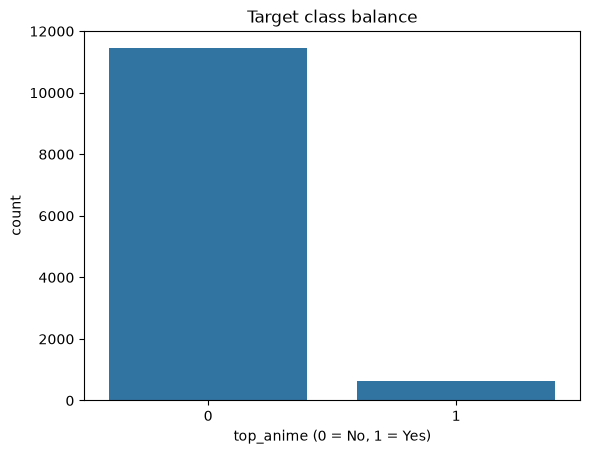

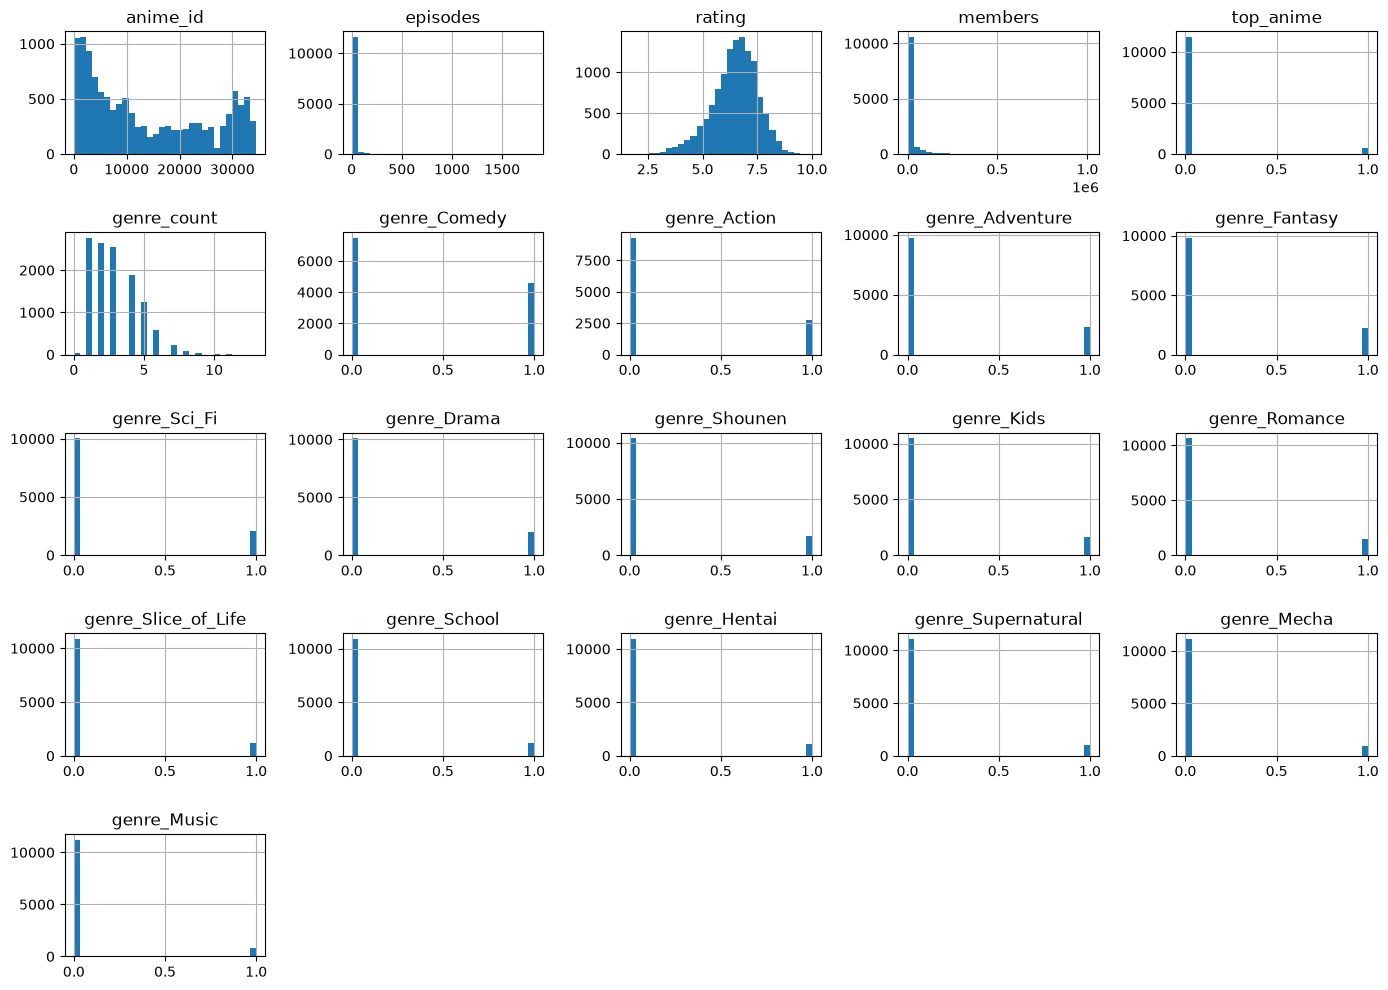

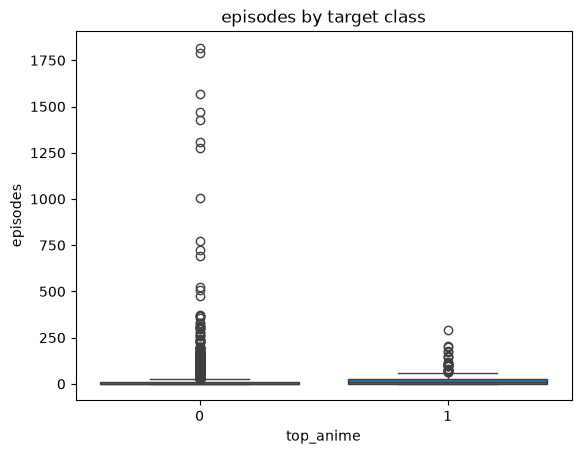

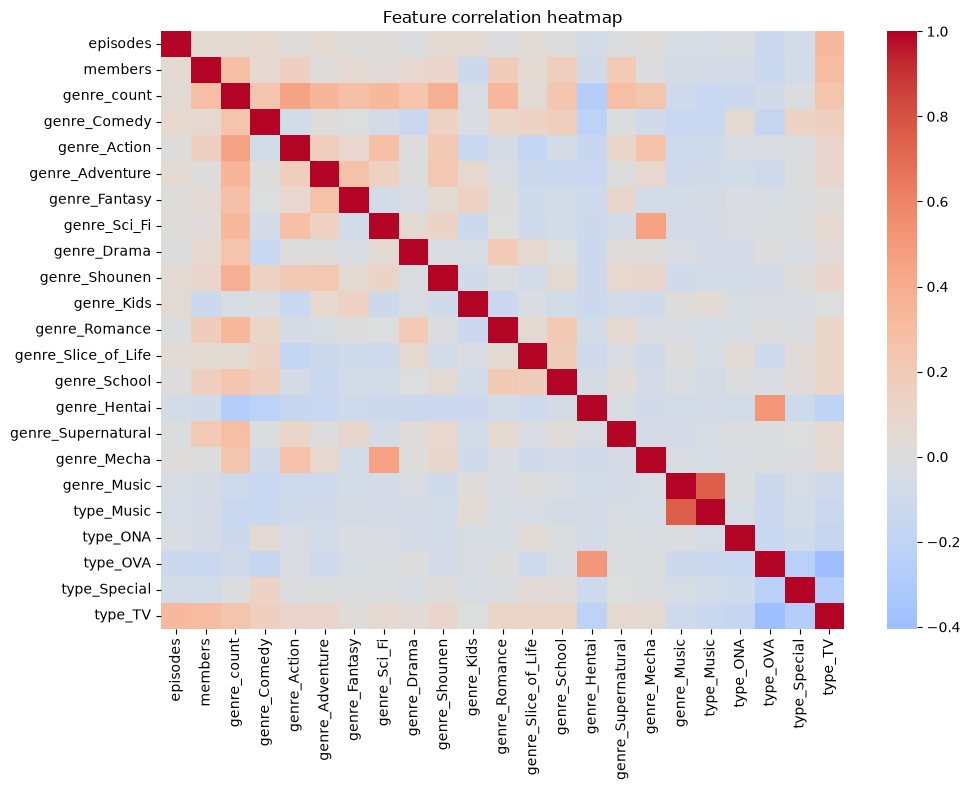

In [6]:
sns.countplot(x=y)
plt.title("Target class balance")
plt.xlabel("top_anime (0 = No, 1 = Yes)")
plt.show()

numeric_for_plot = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_for_plot].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

# Plot a useful numeric variable, if one is available.
candidate_cols = [c for c in X.columns if X[c].nunique() > 1]
if candidate_cols:
    plot_col = candidate_cols[0]
    sns.boxplot(x=y, y=X[plot_col])
    plt.title(f"{plot_col} by target class")
    plt.xlabel("top_anime")
    plt.show()

if X.shape[1] > 1:
    plt.figure(figsize=(min(16, max(9, X.shape[1] * 0.45)), 8))
    sns.heatmap(X.corr(), cmap="coolwarm", center=0)
    plt.title("Feature correlation heatmap")
    plt.tight_layout()
    plt.show()

### EDA observations

Write five observations from the charts above. Example: “The positive target class is smaller than the negative class, so the dataset is imbalanced.”

## 7. Train/test split and feature selection

Split first so feature selection is learned only from training data. This avoids using test-set information during training. Keep up to the 15 highest-scoring features.

In [7]:
if y.nunique() != 2:
    raise ValueError("The target must contain both classes (0 and 1) to run this binary classification project.")

X_train_all, X_test_all, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

k = min(15, X_train_all.shape[1])
selector = SelectKBest(score_func=f_classif, k=k)
X_train = selector.fit_transform(X_train_all, y_train)
X_test = selector.transform(X_test_all)
feature_names = X_train_all.columns[selector.get_support()].tolist()

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Selected features:")
print(feature_names)

Training set: (9651, 15)
Test set: (2413, 15)
Selected features:
['members', 'genre_count', 'genre_Action', 'genre_Drama', 'genre_Shounen', 'genre_Romance', 'genre_Slice_of_Life', 'genre_School', 'genre_Hentai', 'genre_Supernatural', 'type_Music', 'type_ONA', 'type_OVA', 'type_Special', 'type_TV']


## 8. Train and evaluate Gaussian Naïve Bayes

The evaluation function reports accuracy, precision, recall, F1, specificity, and ROC-AUC, along with the confusion matrix and classification report.

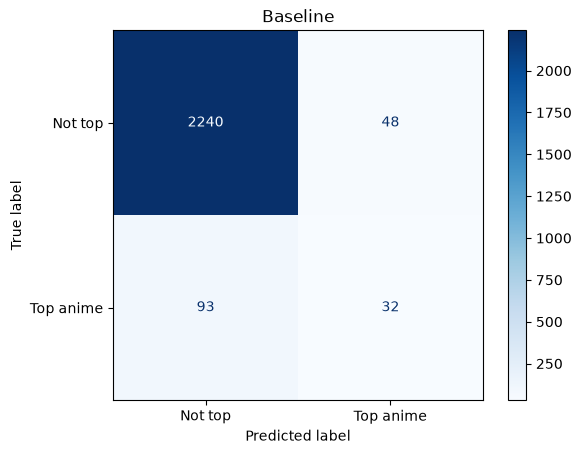

               precision    recall  f1-score   support

Not top anime       0.96      0.98      0.97      2288
    Top anime       0.40      0.26      0.31       125

     accuracy                           0.94      2413
    macro avg       0.68      0.62      0.64      2413
 weighted avg       0.93      0.94      0.94      2413



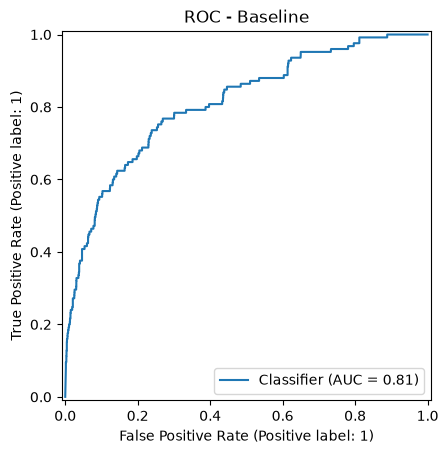

{'Setting': 'Baseline', 'Accuracy': 0.9415665147119768, 'Precision': 0.4, 'Recall': 0.256, 'F1': 0.3121951219512195, 'Specificity': np.float64(0.9790209790209791), 'AUC': 0.8111958041958042}


In [8]:
results = []

def evaluate(name, model, show=False):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    try:
        probabilities = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probabilities)
    except (ValueError, AttributeError):
        probabilities = None
        auc = np.nan

    row = {
        "Setting": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "Specificity": specificity,
        "AUC": auc
    }

    if show:
        ConfusionMatrixDisplay(cm, display_labels=["Not top", "Top anime"]).plot(cmap="Blues")
        plt.title(name)
        plt.show()
        print(classification_report(
            y_test, y_pred, labels=[0, 1],
            target_names=["Not top anime", "Top anime"],
            zero_division=0
        ))
        if probabilities is not None:
            RocCurveDisplay.from_predictions(y_test, probabilities)
            plt.title("ROC - " + name)
            plt.show()

    print(row)
    return row

baseline_model = GaussianNB()
results.append(evaluate("Baseline", baseline_model, show=True))

## 9. Try different GaussianNB settings

`var_smoothing` adds a small amount of variance to stabilize calculations. GaussianNB assumes features are conditionally independent given the class; correlated features in the heatmap show where this assumption may be imperfect.

{'Setting': 'var_smoothing=1e-09', 'Accuracy': 0.9415665147119768, 'Precision': 0.4, 'Recall': 0.256, 'F1': 0.3121951219512195, 'Specificity': np.float64(0.9790209790209791), 'AUC': 0.8111958041958042}
{'Setting': 'var_smoothing=1e-07', 'Accuracy': 0.9428097803564028, 'Precision': 0.4177215189873418, 'Recall': 0.264, 'F1': 0.3235294117647059, 'Specificity': np.float64(0.9798951048951049), 'AUC': 0.8306853146853148}
{'Setting': 'var_smoothing=1e-05', 'Accuracy': 0.9428097803564028, 'Precision': 0.4177215189873418, 'Recall': 0.264, 'F1': 0.3235294117647059, 'Specificity': np.float64(0.9798951048951049), 'AUC': 0.8464999999999999}
Class counts: [9149.  502.]
Class priors: [0.94798466 0.05201534]
Predicted probabilities for up to 3 test samples:


,Class 0,Class 1
0,0.991314,0.008686
1,0.991388,0.008612
2,0.994330,0.005670


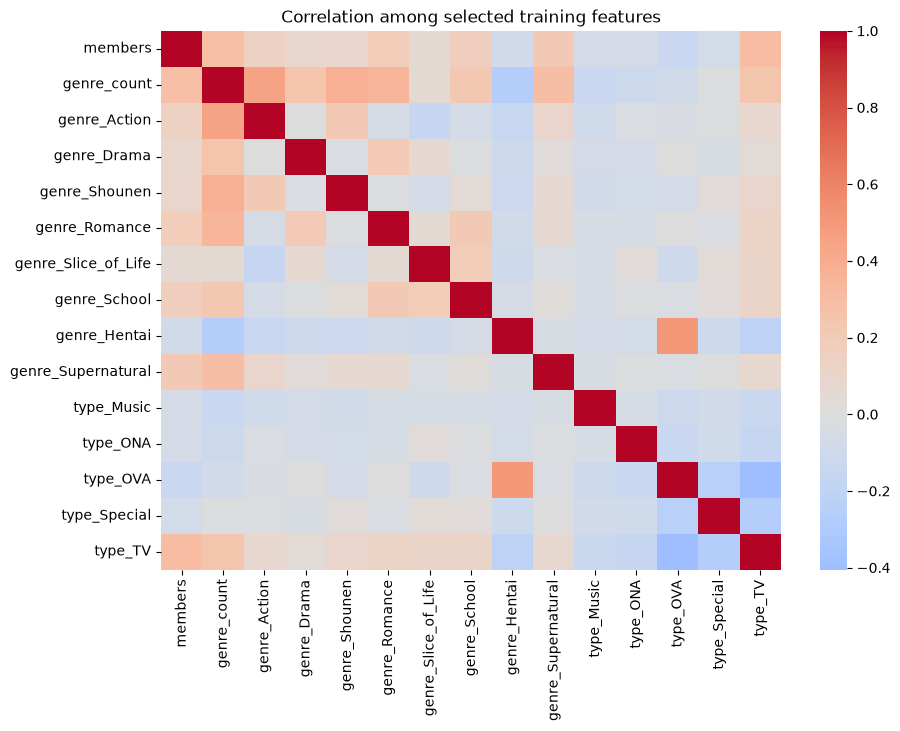

In [9]:
for value in [1e-9, 1e-7, 1e-5]:
    results.append(evaluate(f"var_smoothing={value}", GaussianNB(var_smoothing=value)))

nb = GaussianNB().fit(X_train, y_train)
print("Class counts:", nb.class_count_)
print("Class priors:", nb.class_prior_)
print("Predicted probabilities for up to 3 test samples:")
display(pd.DataFrame(
    nb.predict_proba(X_test[:3]),
    columns=[f"Class {c}" for c in nb.classes_]
))

if len(feature_names) > 1:
    plt.figure(figsize=(10, 7))
    sns.heatmap(pd.DataFrame(X_train, columns=feature_names).corr(),
                cmap="coolwarm", center=0)
    plt.title("Correlation among selected training features")
    plt.show()

## 10. Compare settings and choose the final model

The best setting is selected by F1 score. AUC is also reported to assess ranking/discrimination performance.

,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,var_smoothing=1e-05,0.943,0.418,0.264,0.324,0.980,0.846
1,var_smoothing=1e-07,0.943,0.418,0.264,0.324,0.980,0.831
2,var_smoothing=1e-09,0.942,0.400,0.256,0.312,0.979,0.811
3,Baseline,0.942,0.400,0.256,0.312,0.979,0.811


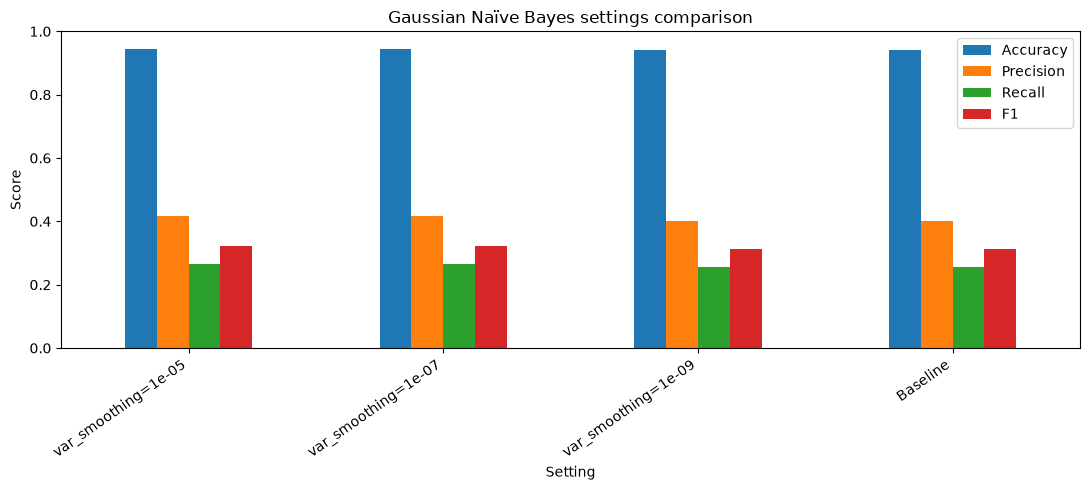

Best setting by F1: var_smoothing=1e-05


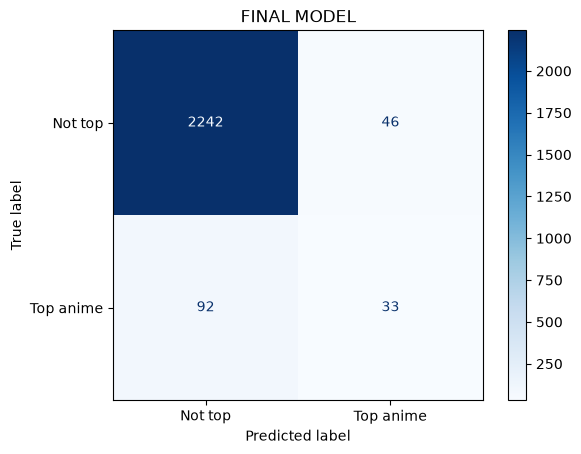

               precision    recall  f1-score   support

Not top anime       0.96      0.98      0.97      2288
    Top anime       0.42      0.26      0.32       125

     accuracy                           0.94      2413
    macro avg       0.69      0.62      0.65      2413
 weighted avg       0.93      0.94      0.94      2413



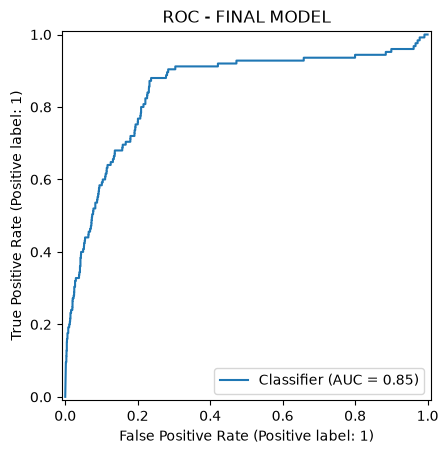

{'Setting': 'FINAL MODEL', 'Accuracy': 0.9428097803564028, 'Precision': 0.4177215189873418, 'Recall': 0.264, 'F1': 0.3235294117647059, 'Specificity': np.float64(0.9798951048951049), 'AUC': 0.8464999999999999}
Final model settings: {'priors': None, 'var_smoothing': 1e-05}


In [10]:
res = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
display(res.round(3))

res.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(11, 5)
)
plt.title("Gaussian Naïve Bayes settings comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

best_setting = res.iloc[0]["Setting"]
print("Best setting by F1:", best_setting)

if best_setting.startswith("var_smoothing="):
    best_value = float(best_setting.split("=")[1])
    final_model = GaussianNB(var_smoothing=best_value)
else:
    final_model = GaussianNB()

final_results = evaluate("FINAL MODEL", final_model, show=True)
print("Final model settings:", final_model.get_params())

## 11. Predict three new examples

These are three held-out dataset examples used to demonstrate prediction. They are not guaranteed to be genuinely new anime records. The model expects the selected feature columns in the same order.

In [11]:
new_samples = X_test_all.iloc[:3].copy()
new_selected = selector.transform(new_samples)
predictions = final_model.predict(new_selected)
probabilities = final_model.predict_proba(new_selected)[:, 1]

prediction_output = pd.DataFrame({
    "Predicted top_anime": predictions,
    "Probability of top_anime": probabilities.round(3)
}, index=new_samples.index)
display(new_samples[feature_names])
display(prediction_output)

,members,genre_count,genre_Action,genre_Drama,genre_Shounen,genre_Romance,genre_Slice_of_Life,genre_School,genre_Hentai,genre_Supernatural,type_Music,type_ONA,type_OVA,type_Special,type_TV
6010,1186.0,3.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4218,312.0,3.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6657,1020.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


,Predicted top_anime,Probability of top_anime
6010,0,0.01
4218,0,0.01
6657,0,0.01


## 12. Conclusion and report notes

Complete this section after running all cells:

1. **Dataset:** State the number of rows and columns, and provide the Kaggle/source URL.
2. **Data preparation:** Explain duplicate removal, missing-value treatment, genre encoding, and dropped leakage/identifier columns.
3. **EDA:** Summarize five chart observations and state whether the target is balanced.
4. **Feature selection:** List the selected features and describe the engineered `genre_count` feature (if genre was available).
5. **Model:** Explain Gaussian Naïve Bayes and its conditional-independence assumption.
6. **Evaluation:** Report final accuracy, precision, recall, F1, specificity, and AUC. Interpret the confusion matrix.
7. **Conclusion:** State what the model can predict, its limitations, and what you learned.

**Important:** Results depend on the exact `anime.csv` file. Do not write numerical results until you have run the notebook.

## 13. Viva preparation

Be ready to explain: target variable, class imbalance, median vs. mode imputation, one-hot encoding, feature engineering, train/test split, stratification, SelectKBest, GaussianNB, the independence assumption, class priors, confusion matrix, precision, recall, F1, specificity, ROC curve, and AUC.